# **Recommendation systems, ICA, and matrix factorization**

**Libraries**
-

In [1]:
from pathlib import Path
import sys
from IPython.display import display

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models.latent_factors import FactorData, FASearch, ICASearch, FactorAnalysisResult, FactorComparison
from src.models.recommendation import RecommendationData, RecommendationSearch, SVDRecommender
from src.models.latent_factor_plots import (
    plot_fa_search, plot_ica_search, plot_fa_loadings, plot_ica_loadings,
    plot_factor_comparison, plot_recommendation_search, plot_product_popularity,
)


## **1. Question of Interest**

### **1.2 Question**

- To what extent can Factor Analysis (FA), PCA, and ICA identify interpretable latent factors underlying commercial sales patterns, how do their representations differ, and how effectively can matrix factorization support customer–product recommendation systems?

### **1.2 Tools that are going to be used**

To continue identifiying latent factors underlying commercial patterns, we are gonna use the next models:
| Criterion           | Factor Analysis (FA)                          | PCA                                       | ICA                                          |
| ------------------- | --------------------------------------------- | ----------------------------------------- | -------------------------------------------- |
| Main objective      | Identify underlying latent factors.           | Maximize explained variance.              | Identify independent latent sources.         |
| Approach            | Probabilistic factor model.                   | Variance-based decomposition.             | Statistical source separation.               |
| Key assumption      | Shared factors explain observed correlations. | High-variance directions are informative. | Sources are statistically independent.       |
| Factor relationship | Correlated or uncorrelated.                   | Orthogonal and uncorrelated.              | Statistically independent.                   |
| Interpretability    | Often easier to interpret.                    | Not necessarily interpretable.            | May reveal distinct hidden patterns.         |
| Main limitation     | Depends on modeling assumptions.              | Variance does not imply relevance.        | Independence assumptions may be unrealistic. |

On the other hand, for implementing a customer Truncated SVD is going to be applied from a customer-product interaction matrix, and finally the recommended system implemented will be compared with the popularity baseline to evaluate performance.

## **2. Database Loading and train/val/test**

### **2.1 Reading CSV**

In [2]:
factor_data = FactorData()
factor_data.frame.head()


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer City,Customer Country,...,Order Item Quantity,Sales,Order Region,Order State,Order Status,Product Card Id,Product Name,Product Price,Shipping Mode,Order Month
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,...,1,327.75,Southeast Asia,Java Occidental,COMPLETE,1360,Smart watch,327.75,Standard Class,1
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,Sporting Goods,Caguas,Puerto Rico,...,1,327.75,South Asia,Rajastán,PENDING,1360,Smart watch,327.75,Standard Class,1
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,Sporting Goods,San Jose,EE. UU.,...,1,327.75,South Asia,Rajastán,CLOSED,1360,Smart watch,327.75,Standard Class,1
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,Sporting Goods,Los Angeles,EE. UU.,...,1,327.75,Oceania,Queensland,COMPLETE,1360,Smart watch,327.75,Standard Class,1
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,...,1,327.75,Oceania,Queensland,PENDING_PAYMENT,1360,Smart watch,327.75,Standard Class,1


In [3]:
factor_data.X.head()


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Order Item Discount,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity,Sales,Product Price
0,3.0,4.0,91.250000,314.640015,13.110000,0.04,0.29,1.0,327.75,327.75
1,5.0,4.0,-249.089996,311.359985,16.389999,0.05,-0.80,1.0,327.75,327.75
2,4.0,4.0,-247.779999,309.720001,18.030001,0.06,-0.80,1.0,327.75,327.75
3,3.0,4.0,22.860001,304.809998,22.940001,0.07,0.08,1.0,327.75,327.75
4,2.0,4.0,134.210007,298.250000,29.500000,0.09,0.45,1.0,327.75,327.75


### **2.2 Split**

In [4]:
display(factor_data.split_summary())


,Dataset,Observations,Features
0,train,126363,10
1,validation,27078,10
2,test,27078,10


### **3.3 Standarize**

In [5]:
factor_data.scaler


StandardScaler()

## **3. Factor Analysis (FA)**

### **3.1 Notation**

FA stands for **Factor Analysis**. It is a probabilistic latent variable model that assumes the observed features can be explained by a smaller number of unobserved factors and Gaussian noise.

FA uses a similar structure to PPCA:

$$
\boxed{X_c=ZW^\top+E}
$$

Where:

- $X_c\in\mathbb R^{n\times p}$ is the centered data matrix.
- $Z\in\mathbb R^{n\times k}$ contains the unobserved latent factors.
- $W\in\mathbb R^{p\times k}$ is the factor loading matrix.
- $E\in\mathbb R^{n\times p}$ represents Gaussian noise.

As in PPCA, we assume that the latent factors follow a standard multivariate Gaussian distribution:

$$
Z_{i,:}^\top\sim\mathcal N(0,I_k)
$$

However, **the main difference between FA and PPCA is the assumption about the noise covariance**.

In PPCA, every feature has the same noise variance, whereas FA allows each feature to have its own noise variance:

$$
\boxed{E_{i,:}^\top\sim\mathcal N(0,\Psi)}
$$

Where:

$$
\Psi=
\begin{bmatrix}
\psi_1&0&\cdots&0\\
0&\psi_2&\cdots&0\\
\vdots&\vdots&\ddots&\vdots\\
0&0&\cdots&\psi_p
\end{bmatrix}
$$

Here, $\psi_j$ represents the specific noise variance associated with feature $j$. The diagonal structure assumes that the noise terms of different features are uncorrelated.

Since the latent factors and noise are independent Gaussian random variables, their linear combination is also Gaussian. Therefore:

$$
\boxed{X_{c,i,:}^\top\sim\mathcal N(0,C)}
$$

With covariance matrix:

$$
\boxed{C=WW^\top+\Psi}
$$

Where:

- $WW^\top$ represents the covariance explained by the common latent factors.
- $\Psi$ represents the feature-specific residual variances, also called *uniquenesses*.
- $C$ represents the covariance matrix assumed by the probabilistic model.

The main difference between PPCA and FA can therefore be summarized as:

$$
\underbrace{C_{\text{PPCA}}=WW^\top+\sigma^2I_p}_{\text{Equal noise variance}}
$$

$$
\underbrace{C_{\text{FA}}=WW^\top+\Psi}_{\text{Feature-specific noise variance}}
$$

Consequently, **FA is more flexible than PPCA in modeling the covariance structure**, because it allows each observed variable to have a different amount of unexplained variance.

Finally, after estimating the model, we can obtain the latent factor scores using their conditional expectation:

$$
\boxed{
\hat Z=X_cC^{-1}W
}
$$

Where $\hat Z$ represents the estimated latent factor scores and $C^{-1}$ is the inverse of the covariance matrix assumed by the model.

We can then reconstruct an approximation of the original matrix:

$$
\boxed{
\hat X=\hat ZW^\top+\mathbf{1}\mu
}
$$

Where $\mu$ is the vector of feature means and $\mathbf{1}$ is a column vector of ones.

Unlike standard PCA, these factor scores are estimated using the probabilistic model, taking both the common factor structure and the feature-specific noise variances into account.

### **3.2 Evaluating different $k$**

In [6]:
fa_search = FASearch(n_jobs=-1, force_retrain=False).run(factor_data)
display(fa_search.results.round(6))


FA: loaded 9; remaining 0


,k,Train MSE,Validation MSE,Train Relative Frobenius,Validation Relative Frobenius,Train Reconstructed Energy,Validation Reconstructed Energy,Stability Mean,Stability Std,Mean Concentration,Silhouette
0,1,0.699277,0.697383,0.836228,0.826561,0.300723,0.316797,0.999978,0.000022,0.275235,NaN
1,2,0.525075,0.525982,0.724620,0.717835,0.474925,0.484713,0.999967,0.000023,0.390735,0.518410
2,3,0.389305,0.388617,0.623943,0.617021,0.610695,0.619285,0.999543,0.000831,0.428429,0.355303
3,4,0.248997,0.248269,0.498996,0.493174,0.751003,0.756779,0.999974,0.000011,0.440789,0.286539
4,5,0.118098,0.116971,0.343654,0.338515,0.881902,0.885407,0.999984,0.000007,0.478433,0.252678
5,6,0.099919,0.097855,0.316100,0.309621,0.900081,0.904135,0.999839,0.000095,0.482455,0.226525
6,7,0.099660,0.097596,0.315690,0.309211,0.900340,0.904389,0.972024,0.037728,0.526736,0.225966
7,8,0.099152,0.097102,0.314884,0.308428,0.900848,0.904872,0.978939,0.011064,0.497922,0.225239
8,9,0.099222,0.097173,0.314996,0.308541,0.900778,0.904803,0.986979,0.007341,0.501776,0.214107


### **3.3 Metrics Visualization**

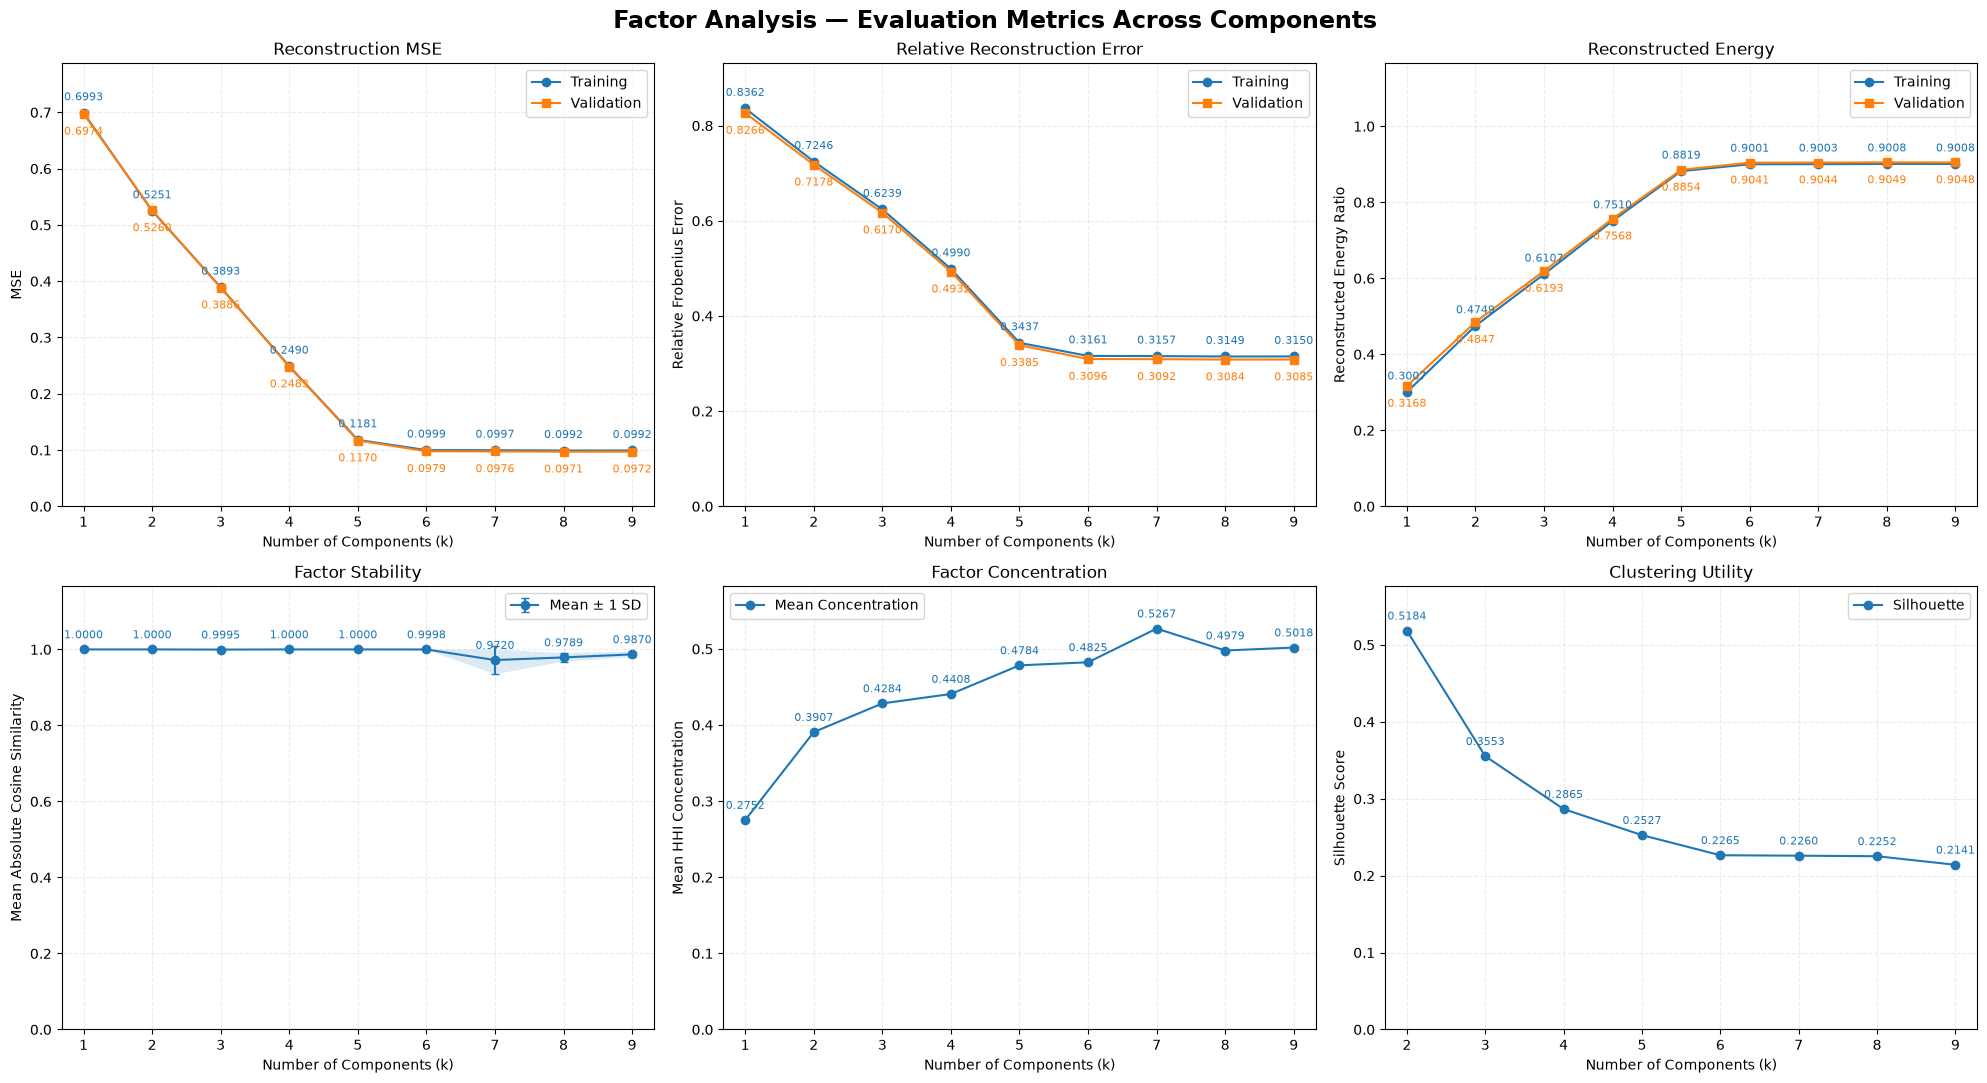

In [7]:
plot_fa_search(fa_search)


**Observations**

We selected **$k=5$ latent factors** based on the following considerations:

- **Reconstruction quality:** With $k=5$, the model achieves approximately 88.54% reconstructed energy on validation data, with a validation MSE of 0.1170 and a relative Frobenius error of 0.3385.
- **Diminishing improvements:** Reconstruction improves substantially between $k=1$ and $k=5$. Although $k=6$ provides a further improvement, additional factors beyond $k=6$ produce negligible reductions in reconstruction error.
- **Factor stability:** At $k=5$, the mean bootstrap factor similarity is approximately 0.99998, indicating that the estimated factor-loading directions remain highly consistent across resampled datasets.
- **Interpretability and complexity:** Five factors provide a compact representation of the dominant patterns in the data while avoiding unnecessary model complexity.

### **3.4 FA with $k=5$**

In [8]:
fa_analysis = FactorAnalysisResult(fa_search, k=5).fit()
display(fa_analysis.loadings.round(4))
display(fa_analysis.metrics.round(6))
display(fa_analysis.scores["train"].head())


,Factor 1,Factor 2,Factor 3,Factor 4,Factor 5
Days for shipping (real),0.0001,0.0021,0.0010,0.0029,-0.7169
Days for shipment (scheduled),0.0054,-0.0008,0.0034,0.0019,-0.7171
Benefit per order,0.1008,0.0037,-0.0082,-0.9067,0.0015
Sales per customer,0.9959,0.0194,-0.0830,-0.0304,-0.0013
Order Item Discount,0.4783,0.8776,-0.0294,-0.0116,-0.0001
Order Item Discount Rate,-0.1343,0.8278,0.0207,0.0080,-0.0009
Order Item Profit Ratio,-0.0285,0.0013,0.0038,-0.9103,0.0014
Order Item Quantity,0.0275,0.0288,-0.9581,-0.0068,0.0017
Sales,0.9830,0.1623,-0.0802,-0.0295,-0.0012
Product Price,0.8239,0.1210,0.5247,-0.0211,-0.0018


,Dataset,MSE,Relative Frobenius,Reconstructed Energy
0,Train,0.118098,0.343654,0.881902
1,Validation,0.116971,0.338515,0.885407
2,Test,0.115917,0.343590,0.881946


,Factor 1,Factor 2,Factor 3,Factor 4,Factor 5
99963,-0.476822,0.609502,-0.556707,2.773214,-0.404824
63538,0.220011,-0.564896,0.744039,0.335818,-0.221410
6661,-0.342156,0.586508,-0.630678,-0.402132,0.066074
93913,-0.671515,1.012376,0.724357,0.148825,-0.515561
90626,-0.598350,0.636909,0.712824,0.540183,-0.222894


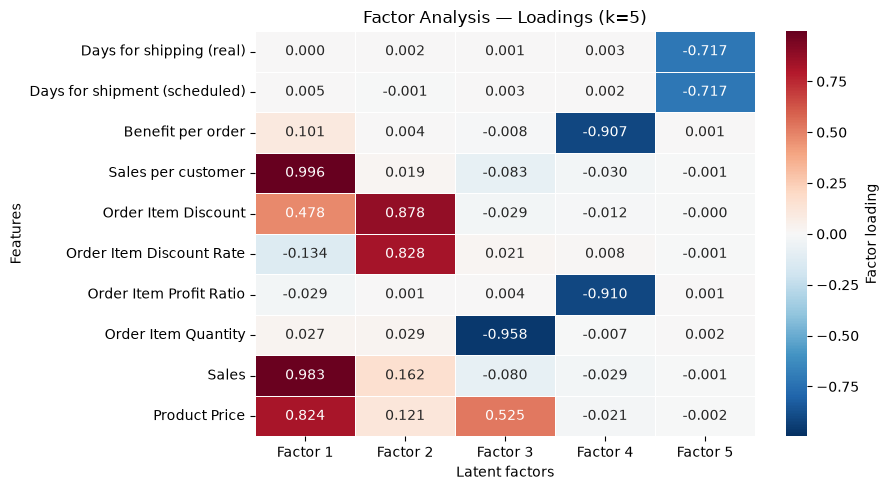

In [9]:
plot_fa_loadings(fa_analysis)


**Observations**

- **Factor 1 — Sales Value and Product Price:** This factor is characterized by strong positive loadings for Sales per Customer (0.996), Sales (0.983), and Product Price (0.824), along with a moderate positive loading for Order Item Discount (0.478). It may represent the monetary value of transactions, particularly those involving higher-priced products and larger absolute discounts.

- **Factor 2 — Discounts:** This factor is dominated by strong positive loadings for Order Item Discount (0.878) and Order Item Discount Rate (0.828). It may capture the discount intensity of transactions, identifying observations associated with larger discounts in both absolute and relative terms.

- **Factor 3 — Product Price versus Quantity:** This factor exhibits a strong negative loading for Order Item Quantity (-0.958) and a moderate positive loading for Product Price (0.525). It may represent a contrast between product price and purchased quantity, where higher factor scores are associated with higher-priced products purchased in smaller quantities.

- **Factor 4 — Profitability:** This factor is characterized by strong negative loadings for Order Item Profit Ratio (-0.910) and Benefit per Order (-0.907). Higher factor scores are associated with lower profitability indicators, potentially identifying less profitable transactions. 

- **Factor 5 — Shipping Duration:** This factor is dominated by negative loadings for Days for Shipping (Real) (-0.717) and Days for Shipment (Scheduled) (-0.717). Higher factor scores are associated with shorter actual and scheduled shipping durations.

## **4. Independent Component Analysis (ICA)**

### **4.1 Notation**


ICA stands for **Independent Component Analysis**. It is a statistical technique that assumes the observed variables are generated by linear combinations of latent sources that are statistically independent.

ICA assumes that the centered data matrix can be represented as:

$$
\boxed{X_c=SA^\top}
$$

Where:

- $X_c\in\mathbb R^{n\times p}$ is the centered data matrix.
- $S\in\mathbb R^{n\times k}$ contains the unobserved independent components.
- $A\in\mathbb R^{p\times k}$ is the mixing matrix.

The main objective of ICA is to estimate the independent sources $S$ from the observed data $X_c$.

Unlike PCA, which finds uncorrelated components that maximize variance, **ICA searches for components that are statistically independent**.

This means that the joint probability distribution of the sources can be expressed as:

$$
\boxed{
p(s_1,s_2,\ldots,s_k)=\prod_{j=1}^{k}p(s_j)
}
$$

To identify these independent sources, ICA assumes that they are **non-Gaussian**, with at most one Gaussian component. This is important because mixtures of independent variables tend to be more Gaussian than the original sources under suitable conditions, as suggested by the Central Limit Theorem.

Therefore, ICA searches for directions that maximize non-Gaussianity as a way to recover independent components.

Before estimating these components, ICA typically applies **whitening**, which transforms the centered observations so that their covariance matrix becomes the identity matrix:

$$
\boxed{X_w=X_cV_k\Lambda_k^{-1/2}}
$$

Where $V_k$ contains the selected eigenvectors of the covariance matrix and $\Lambda_k$ contains their corresponding eigenvalues.

After whitening, ICA estimates an unmixing matrix $B$ that produces the independent components:

$$
\boxed{\hat S=X_wB^\top}
$$

The unmixing matrix is estimated through an optimization procedure that maximizes a measure of non-Gaussianity, such as an approximation of negentropy.

Finally, the original data can be approximately reconstructed using the estimated independent components and the mixing matrix:

$$
\boxed{\hat X=\hat SA^\top+\mathbf 1\mu}
$$

Where $\mu$ represents the vector of feature means.

Consequently, **ICA differs from PCA and FA because its primary objective is not to maximize explained variance or model shared covariance, but to identify statistically independent latent sources underlying the observed variables**.


### **4.2 Evaluating different $k$**

In [10]:
ica_search = ICASearch(n_jobs=-1, force_retrain=False).run(factor_data)
display(ica_search.results.round(6))
display(ica_search.results[["k", "Converged", "Iterations"]])


ICA: loaded 0; remaining 9
Saved ICA k=1
Saved ICA k=2
Saved ICA k=3
Saved ICA k=4
Saved ICA k=5
Saved ICA k=6
Saved ICA k=7
Saved ICA k=8
Saved ICA k=9


,k,Train MSE,Train Relative Frobenius,Train Reconstructed Energy,Validation MSE,Validation Relative Frobenius,Validation Reconstructed Energy,Stability Mean,Stability Std,Mean Concentration,Silhouette,Mean Absolute Kurtosis,Converged,Iterations
0,1,0.683911,0.826989,0.316089,0.681441,0.817059,0.332415,0.999924,0.000087,0.245774,NaN,32.209187,True,1
1,2,0.502790,0.709077,0.497210,0.503286,0.702177,0.506948,0.999856,0.000089,0.354022,0.531067,22.973282,True,4
2,3,0.351382,0.592775,0.648618,0.350162,0.585698,0.656958,0.999095,0.001466,0.401596,0.371927,15.469887,True,7
3,4,0.204285,0.451979,0.795715,0.201825,0.444658,0.802279,0.957879,0.064198,0.423289,0.275964,11.808957,True,4
4,5,0.081028,0.284654,0.918972,0.078985,0.278170,0.922621,0.988024,0.035784,0.480350,0.209999,9.597406,True,6
5,6,0.032439,0.180110,0.967561,0.030676,0.173355,0.969948,0.980057,0.039808,0.605581,0.190261,8.346984,True,10
6,7,0.015549,0.124697,0.984451,0.016273,0.126261,0.984058,0.992720,0.021555,0.593897,0.175888,15.865391,True,10
7,8,0.003508,0.059224,0.996492,0.003507,0.058616,0.996564,0.999865,0.000085,0.572512,0.158305,27.724908,True,9
8,9,0.000000,0.000003,1.000000,0.000000,0.000003,1.000000,0.978687,0.032388,0.553856,0.152078,27.700295,True,12


,k,Converged,Iterations
0,1,True,1
1,2,True,4
2,3,True,7
3,4,True,4
4,5,True,6
5,6,True,10
6,7,True,10
7,8,True,9
8,9,True,12


### **4.3 Metrics Visualization**

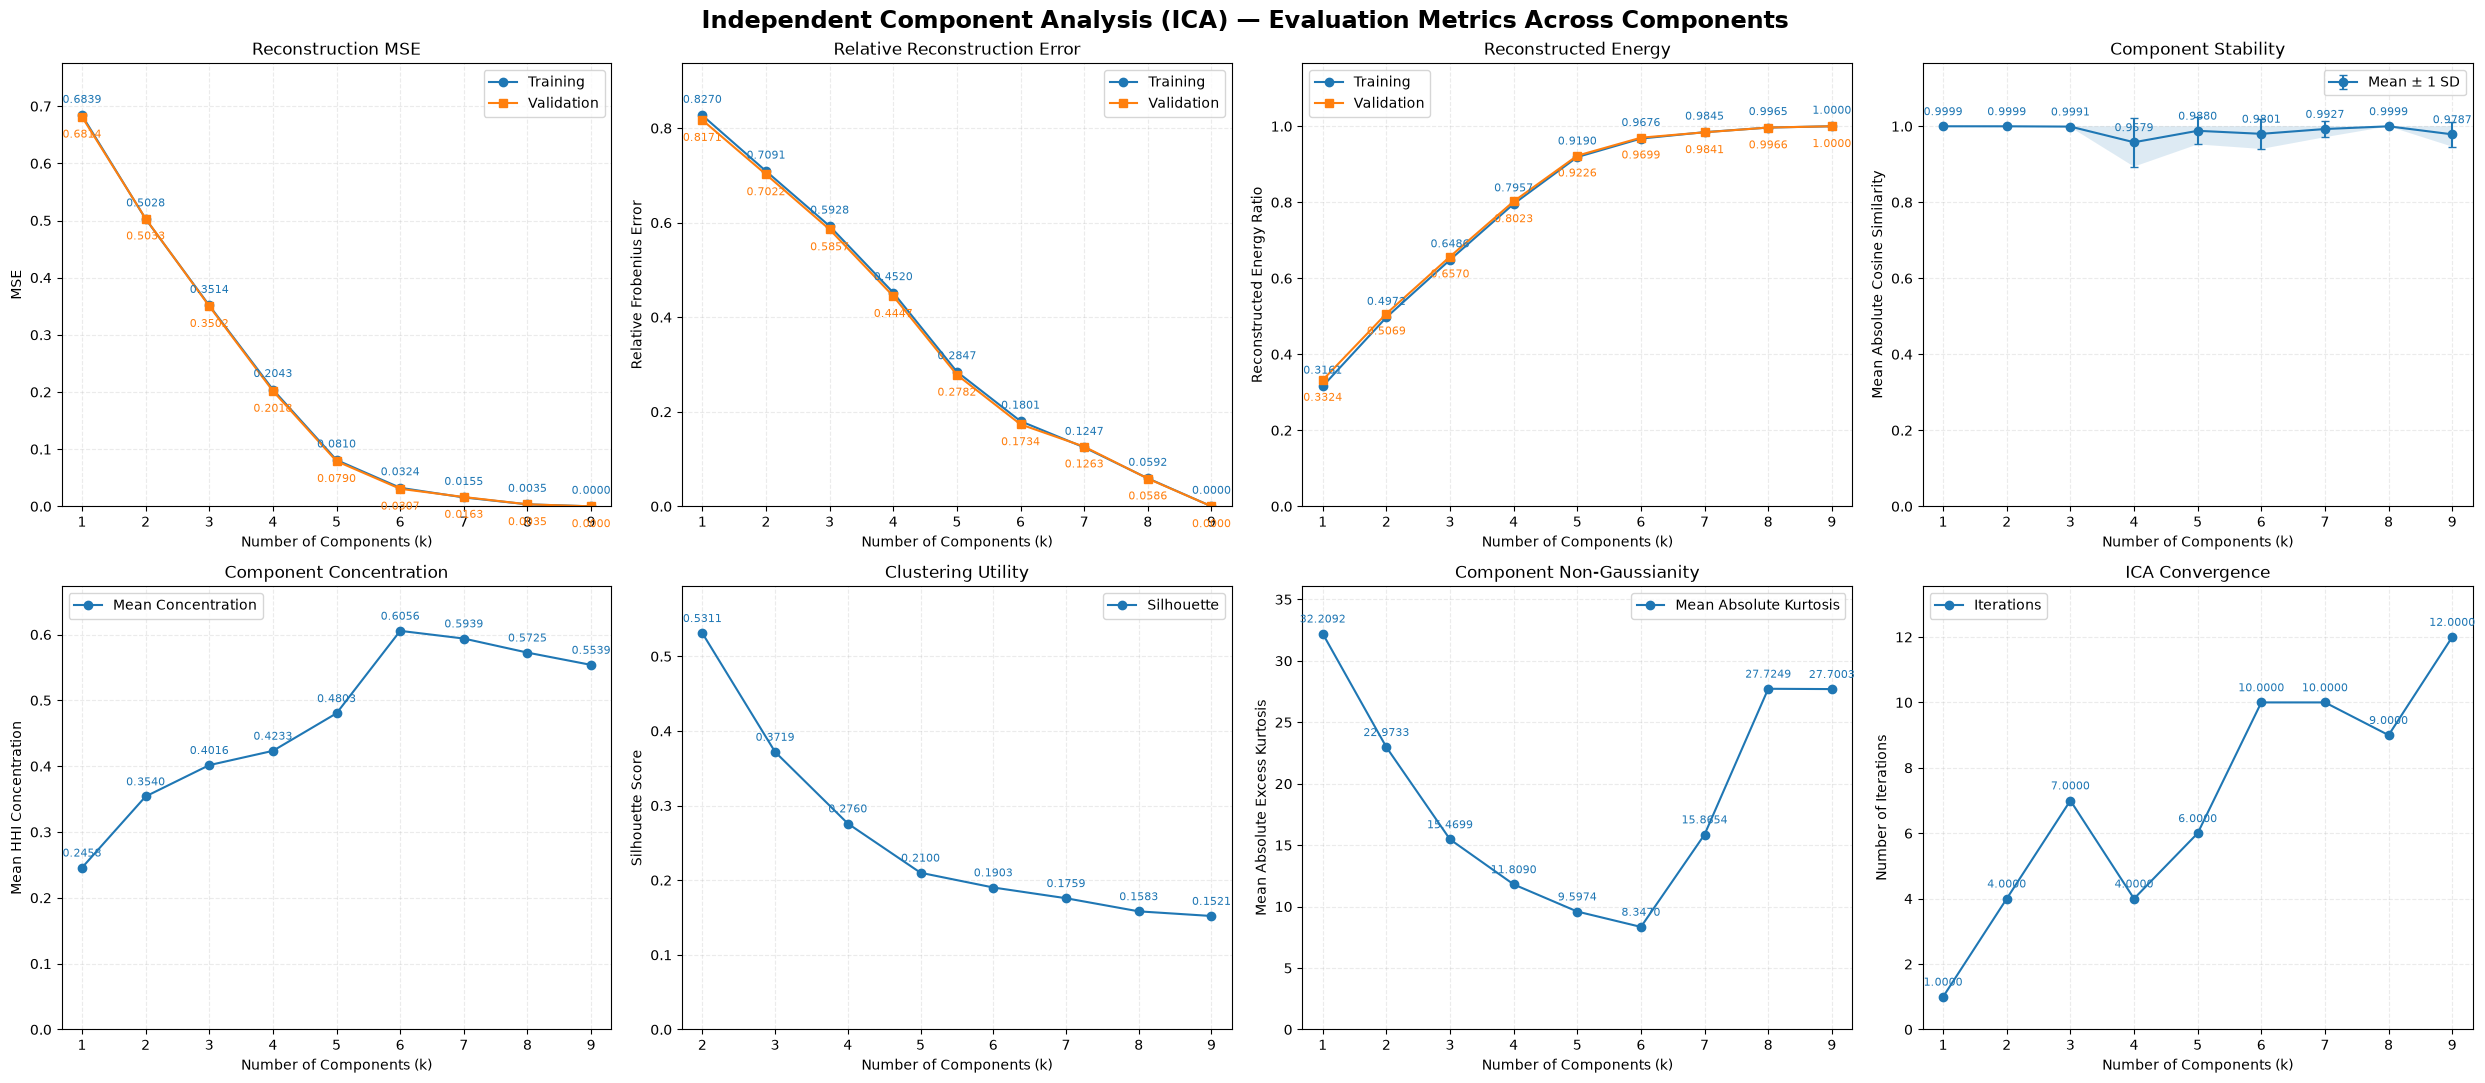

In [11]:
plot_ica_search(ica_search)


**Observations**

We selected **$k=5$ independent components** based on the following considerations:

- **Reconstruction quality:** With $k=5$, ICA achieves approximately 92.26% reconstructed energy on validation data, indicating that five components retain a substantial proportion of the original data's squared norm.
- **Reconstruction error:** The validation MSE decreases to approximately 0.0790, while the relative Frobenius error reaches approximately 0.2782. Although additional components improve reconstruction, five components provide a relatively compact representation.
- **Component stability:** The mean bootstrap component similarity is approximately 0.9880, indicating that the estimated mixing directions are highly consistent across resampled training datasets.
- **Component concentration:** The mean concentration is approximately 0.4805, suggesting that the components exhibit moderately concentrated mixing coefficients across the original variables.
- **Model complexity:** Although larger configurations improve reconstruction, five components were selected to balance dimensionality reduction, reconstruction quality, and stability.


### **4.4 Independent Component Analysis (ICA) $k=5$**

,IC 1,IC 2,IC 3,IC 4,IC 5
Days for shipping (real),0.0048,0.0030,-0.0003,0.8701,0.0028
Days for shipment (scheduled),0.0007,0.0027,0.0031,0.8700,0.0084
Benefit per order,-0.0414,-0.9225,-0.0268,-0.0018,0.2481
Sales per customer,-0.1839,0.1268,-0.1048,-0.0018,0.9627
Order Item Discount,0.7021,0.0765,-0.0877,-0.0044,0.6536
Order Item Discount Rate,0.9774,-0.0092,-0.0175,-0.0024,0.0422
Order Item Profit Ratio,-0.0133,-0.9502,-0.0085,-0.0013,0.1169
Order Item Quantity,-0.0220,0.0096,-0.9958,-0.0020,0.0011
Sales,-0.0512,0.1277,-0.1096,-0.0024,0.9818
Product Price,-0.0340,0.1057,0.4944,-0.0011,0.8492


,Dataset,MSE,Relative Frobenius,Reconstructed Energy
0,Train,0.081028,0.284654,0.918972
1,Validation,0.078985,0.278170,0.922621
2,Test,0.079776,0.285037,0.918754


,Component,Excess Kurtosis,Absolute Kurtosis
0,IC 1,-0.271511,0.271511
1,IC 2,14.948113,14.948113
2,IC 3,-0.696830,0.696830
3,IC 4,-0.447857,0.447857
4,IC 5,31.622719,31.622719


,IC 1,IC 2,IC 3,IC 4,IC 5
99963,1.025795,2.819280,-0.585250,0.489559,-0.771202
63538,-0.593387,0.369526,0.796690,0.269821,0.066977
6661,0.775527,-0.468717,-0.636395,-0.081721,-0.184050
93913,1.862466,0.020825,0.748367,0.620911,-0.466167
90626,1.249913,0.446557,0.754245,0.267763,-0.522952


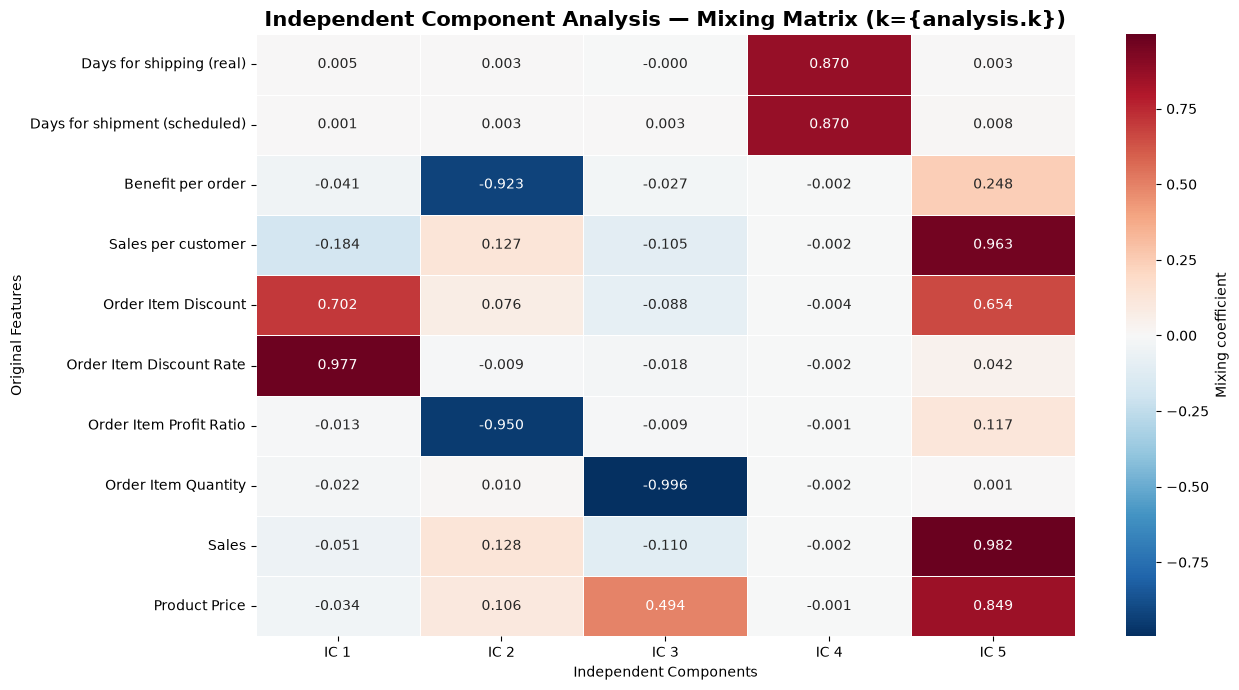

In [12]:
ica_analysis = FactorAnalysisResult(ica_search, k=5).fit()
display(ica_analysis.loadings.round(4))
display(ica_analysis.metrics.round(6))
display(ica_analysis.kurtosis.round(6))
display(ica_analysis.scores["train"].head())
plot_ica_loadings(ica_analysis)


**Observations**

- **IC 1 — Discount Intensity:** This component is dominated by strong positive mixing coefficients for Order Item Discount Rate (0.977) and Order Item Discount (0.702). Higher component scores are associated with higher discount rates and larger absolute discounts, suggesting that this component captures discount-related purchasing patterns.

- **IC 2 — Profitability:** This component is characterized by strong negative mixing coefficients for Order Item Profit Ratio (-0.950) and Benefit per Order (-0.923). Higher component scores are associated with lower profitability indicators, potentially representing transactions with reduced profitability. However, this does not necessarily imply that these transactions generate losses.

- **IC 3 — Price–Quantity Contrast:** This component exhibits a strong negative coefficient for Order Item Quantity (-0.996) and a moderate positive coefficient for Product Price (0.494). Higher component scores are associated with lower purchased quantities and higher product prices, suggesting a contrast between product price and purchase volume.

- **IC 4 — Shipping Duration:** This component is dominated by strong positive coefficients for Days for Shipping (Real) (0.870) and Days for Shipment (Scheduled) (0.870). Higher component scores are associated with longer actual and scheduled shipping durations, potentially capturing variation in overall delivery times.

- **IC 5 — Transaction Value and Discounts:** This component is characterized by strong positive coefficients for Sales (0.982), Sales per Customer (0.963), and Product Price (0.849), along with a substantial positive coefficient for Order Item Discount (0.654). Higher component scores are associated with greater transaction values, higher-priced products, and larger absolute discounts.

## **5. Principal Component Analysis (PCA)** 

Remembering the things were done in 03_svd_pca_probabilistic_lsa.ipynb, we could identify some latent variables in PCA with $k=5$ components that resulted in:

- **Component 1 — High Sales and Discounts:** This component appears to capture positive contributions from Sales per customer, order item discount, sales and product price. It appears to involve products that have an elevated price, greater sales values, and larger absolute discount amounts.

- **Component 2 — Profitability:** This component is dominated by Benefit per order and Order Item Profit Ratio, where we can suggest that this component represents the orders that have high profitability.

- **Component 3 — Shipping Duration:** This component is dominated Days for shipping (real) and Days for shipment (schedule), it appears to describe the orders with longer scheduled and actual shipping durations.

- **Component 4 — Discounts and Relatively Low Sales:** This component captures positive and higher contributions of Order Item Discount Rate and Order Item Discount while small and negative contributions with Sales, Product Price and Sales per costumer. This component could represent the orders that have a high discount, but they get relatively lower sales values to the company.

- **Component 5 - Quantity:** This component has a strong positive contribution with Order Item quantity, a positive but not strong with sales and sales per costumer, but a negative contribution with order item discount rate and product price. This suggest that the component could represent the orders that usually have a low price per product without a high discount, but they have a larger quantities per order, associated with modestly higher sales values.

## **6. ICA vs FA vs PCA Final Comparison**

### **6.1 Metrics and Latent Variables**

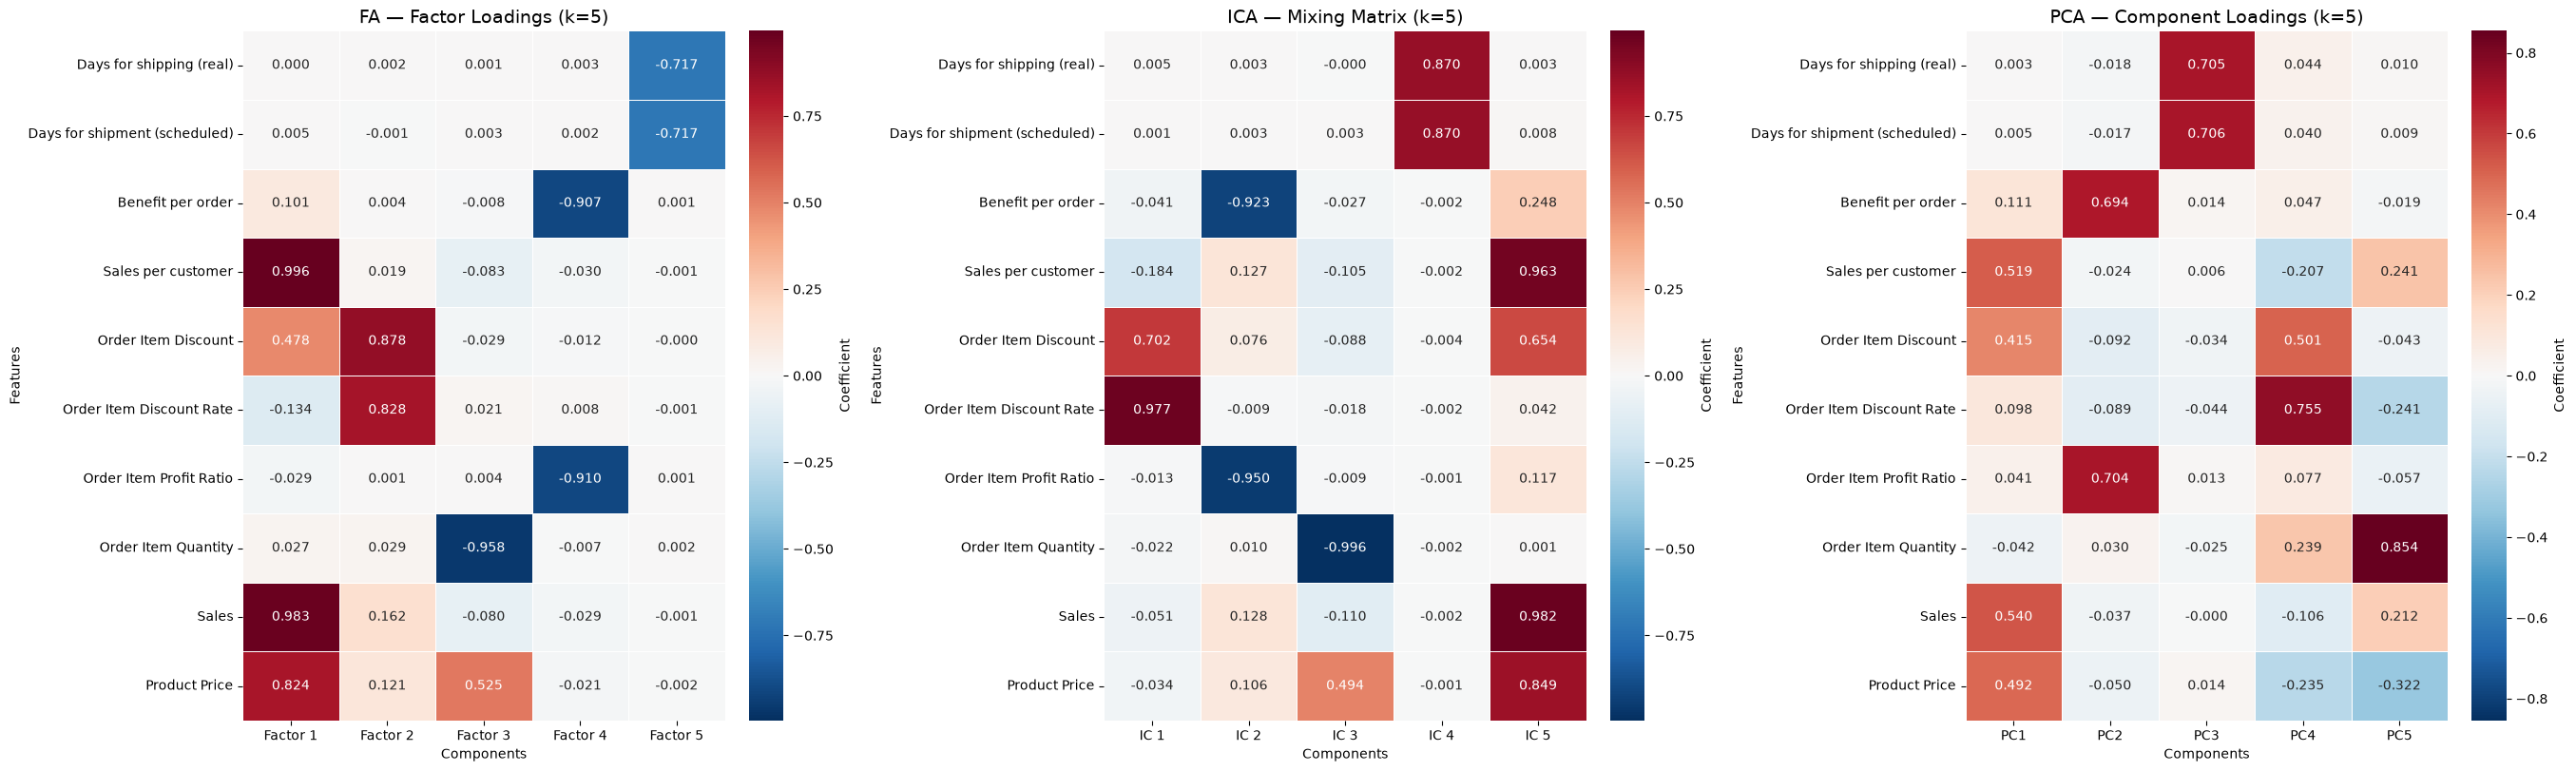

In [13]:
factor_comparison = FactorComparison(fa_analysis, ica_analysis, pca_k=5).run()
plot_factor_comparison(factor_comparison)


**Observations — Comparison of PCA, FA, and ICA**

- **Similar latent patterns:** The three methods identify comparable commercial dimensions associated with transaction value, profitability, discount intensity, shipping duration, and purchased quantity.

- **FA and ICA similarity:** Factor Analysis and ICA produce particularly similar loading and mixing patterns, with several components dominated by nearly the same original variables. This suggests that both methods recover comparable underlying structures despite their different statistical objectives.

- **PCA differences:** PCA identifies similar commercial patterns but distributes some variables differently across its components. In particular, the relationship between product price and purchased quantity is represented differently than in FA and ICA, reflecting PCA's objective of maximizing explained variance.

- **Interpretability:** FA and ICA provide relatively distinct components associated with specific commercial characteristics. PCA also produces interpretable components, although some represent broader combinations of variables.

- **Overall conclusion:** The results suggest that the dominant commercial patterns are consistently identifiable across the three methods. However, FA and ICA provide more closely aligned representations, while PCA emphasizes directions of maximum variance rather than the separation of latent sources.

### **6.2 Quality**

In [14]:
display(factor_comparison.results.round(6))


,Algorithm,Components,Dataset,MSE,Relative Frobenius,RMSE,Reconstructed Energy
0,FA,5,Train,0.118098,0.343654,0.343654,0.881902
1,FA,5,Validation,0.116971,0.338515,0.342010,0.885407
2,FA,5,Test,0.115917,0.343590,0.340466,0.881946
3,ICA,5,Train,0.081028,0.284654,0.284654,0.918972
4,ICA,5,Validation,0.078985,0.278170,0.281042,0.922621
5,ICA,5,Test,0.079776,0.285037,0.282446,0.918754
6,PCA,5,Train,0.081028,0.284654,0.284654,0.918972
7,PCA,5,Validation,0.078985,0.278170,0.281042,0.922621
8,PCA,5,Test,0.079776,0.285037,0.282446,0.918754


**Observations**

- PCA and ICA achieve lower reconstruction errors than Factor Analysis (FA), indicating that they preserve more information from the original dataset when reducing its dimensionality to five components. However, this does not necessarily imply that they produce more useful or interpretable latent representations.

- The latent factor analysis reveals that ICA and FA identify highly similar components associated with commercial characteristics, including transaction value, profitability, discount intensity, shipping duration, and the price–quantity relationship. PCA identifies comparable patterns, although some of its components combine contributions from a broader set of original variables.

- The relatively low reconstruction errors indicate that the models provide good approximations of the original data while preserving relevant information. Additionally, the extracted latent factors reveal meaningful transactional patterns, supporting the quality and interpretability of the resulting representations.

### **6.3 Utility and Interpretability**

The extracted latent factors have potential utility for commercial analysis, as they summarize transaction value, profitability, discount intensity, shipping duration, and the relationship between product prices and purchased quantities. These dimensions could support transaction segmentation, promotional analysis, pricing strategies, and logistics-related decision-making.

Potential applications include:

- **Transaction Value:** Segment transactions into different monetary-value groups to identify purchasing patterns and distinguish between low-value and high-value transactions.
- **Profitability:** Identify transactions associated with lower or higher profitability, supporting the development of strategies to improve financial performance.
- **Discount Intensity:** Analyze promotional patterns and examine how purchasing behavior varies across transactions with different discount levels.
- **Shipping Duration:** Identify orders with longer or shorter shipping times to support the development of more efficient delivery strategies.
- **Price–Quantity Relationship:** Analyze purchasing patterns involving product prices and quantities sold, providing insights that could support pricing and sales strategies.

On the other hand, ICA and FA provide relatively interpretable latent representations, with several components strongly associated with specific groups of commercial variables. PCA identifies similar patterns, although some principal components combine contributions from a broader set of features.

Finally, the consistency of the main commercial dimensions across the three algorithms supports the interpretability of the extracted representations, suggesting that these patterns are not exclusive to a single decomposition method.



## **7. Recommender System**

In [15]:
recommendation_data = RecommendationData(factor_data.frame)


### **7.1 Customer-Product Interaction Matrix**

In [16]:
print("Interaction matrix:", recommendation_data.matrix.shape)
print("Observed interactions:", recommendation_data.matrix.nnz)


Interaction matrix: (20652, 118)
Observed interactions: 101196


In [17]:
display(recommendation_data.activity_summary())


,Products per customer,Customers per product
count,20652.000000,118.000000
mean,4.900058,857.593220
std,3.762009,2257.077398
min,1.000000,8.000000
25%,1.000000,65.000000
50%,5.000000,280.000000
75%,8.000000,307.750000
max,17.000000,10046.000000


### **7.2 Train/Val/Test Split**

In [18]:
recommendation_data.split()
display(recommendation_data.split_summary.round(2))


,Dataset,Interactions,Customers,Products,Percentage
0,Train,77053,20652,118,76.14
1,Validation,11943,11943,99,11.80
2,Test,12200,12200,98,12.06


### **7.3 Truncated SVD with different $k$**

We approximate the customer–product interaction matrix as:
$$
R \approx U_k\Sigma_k V_k^\top
$$

Where:
- $U_k$: Customer latent factors.
- $\Sigma_k$: Singular values.
- $V_k$: Product latent factors.
- $k$: Number of latent dimensions.
In scikit-learn, fit_transform() returns $U_k\Sigma_k$, while components_.T corresponds to $V_k$.R

In [19]:
recommendation_search = RecommendationSearch().run(recommendation_data)
display(recommendation_search.results.round(6))


,k,HitRate@10,NDCG@10,Explained Variance
0,2,0.825253,0.536546,0.585732
1,3,0.767479,0.492952,0.720079
2,5,0.673198,0.462668,0.870238
3,8,0.210249,0.172171,0.913094
4,10,0.034162,0.015836,0.923315
5,15,0.031567,0.014716,0.931935
6,20,0.027464,0.012968,0.940139
7,30,0.028217,0.012566,0.955953
8,40,0.028217,0.013065,0.970818
9,50,0.018002,0.008813,0.984641


#### **7.3.1 Metrics Visualization**

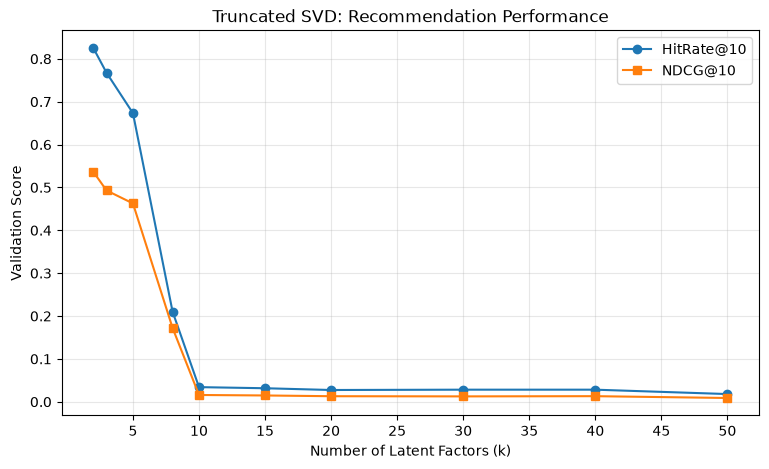

In [20]:
plot_recommendation_search(recommendation_search)


**Observations**

- $k=2$ is the best option among the evaluated values, as it maximizes both HitRate@10 and NDCG@10. The HitRate@10 is approximately 82.53%, indicating that the system successfully includes the held-out product among its top 10 recommendations for nearly 83% of evaluated customers. On the other hand, NDCG@10 reaches approximately 0.54, indicating moderate ranking quality. Although the system frequently identifies the relevant product, its position within the recommendation list can still be improved. Nevertheless, $k=2$ achieves the best ranking performance among the evaluated configurations.

### **7.4 Latent Factors**

In [21]:
recommender = SVDRecommender(k=2, top_k=10).fit(recommendation_data)
product_factors = recommender.product_factors()
display(recommender.factor_extremes())
display(product_factors.select_dtypes("number").corr())


,Component,Direction,Product Card Id,Product Name,Popularity,Coefficient
0,Factor 1,Highest,365,Perfect Fitness Perfect Rip Deck,8643,6.060948e-01
1,Factor 1,Highest,502,Nike Men's Dri-FIT Victory Golf Polo,8210,5.022728e-01
2,Factor 1,Highest,1014,O'Brien Men's Neoprene Life Vest,7932,4.521549e-01
3,Factor 1,Highest,191,Nike Men's Free 5.0+ Running Shoe,6413,2.626621e-01
4,Factor 1,Highest,627,Under Armour Girls' Toddler Spine Surge Runni,5914,2.268157e-01
5,Factor 1,Highest,403,Nike Men's CJ Elite 2 TD Football Cleat,8353,1.474808e-01
6,Factor 1,Highest,1004,Field & Stream Sportsman 16 Gun Fire Safe,7525,1.144244e-01
7,Factor 1,Highest,1073,Pelican Sunstream 100 Kayak,7219,1.025563e-01
8,Factor 1,Highest,957,Diamondback Women's Serene Classic Comfort Bi,6752,9.208993e-02
9,Factor 1,Highest,926,Glove It Imperial Golf Towel,272,6.921962e-03


,Factor 1,Factor 2,Popularity
Factor 1,1.000000,0.008754,0.852614
Factor 2,0.008754,1.000000,-0.071622
Popularity,0.852614,-0.071622,1.000000


**Observations**

- Factor 1 presents a strong positive correlation with product popularity ((r=0.8526)), suggesting that this latent dimension primarily captures the dominant interaction patterns associated with frequently purchased products.
- Factor 2 has almost a nule correlation with popularity ((r=-0.0716)) and presents contrasting coefficients among highly popular products. Perfect Fitness Rip Deck has a strong positive coefficient ((0.7629)), while Nike Golf Polo ((-0.5496)) and O'Brien Life Vest ((-0.3265)) have strong negative coefficients. Factor 2 could be identifying differences in interaction patterns on some popular products.
- Since both factors are strongly influenced by a small group of highly interacted-with products, the imbalance in the interaction matrix may be limiting the model's ability to identify more diverse preference patterns.

### **7.5 Evaluation of the System with $k=2$**

#### **7.5.1 Recommender System Implemented vs Popularity Baseline**

In [22]:
display(recommender.evaluate().round(6))


,Model,HitRate@10,NDCG@10
0,Popularity Baseline,0.850738,0.657241
1,Truncated SVD (k=2),0.829836,0.580999


**Observations**

- The Popularity Baseline achieved higher performance metrics than the implemented recommendation system based on Truncated SVD. One possible explanation is the imbalance in the customer–product interaction matrix, where certain products are purchased much more frequently than others. Consequently, recommending the most popular products can be more effective than using the latent factors identified by SVD to predict customer preferences.

#### **7.5.2 Imbalance of Products**

,Top Products,Interaction Share (%)
0,1,9.93
1,5,46.57
2,10,77.25
3,20,82.43


count      118.000000
mean       857.593220
std       2257.077398
min          8.000000
25%         65.000000
50%        280.000000
75%        307.750000
max      10046.000000
Name: Customer Id, dtype: float64

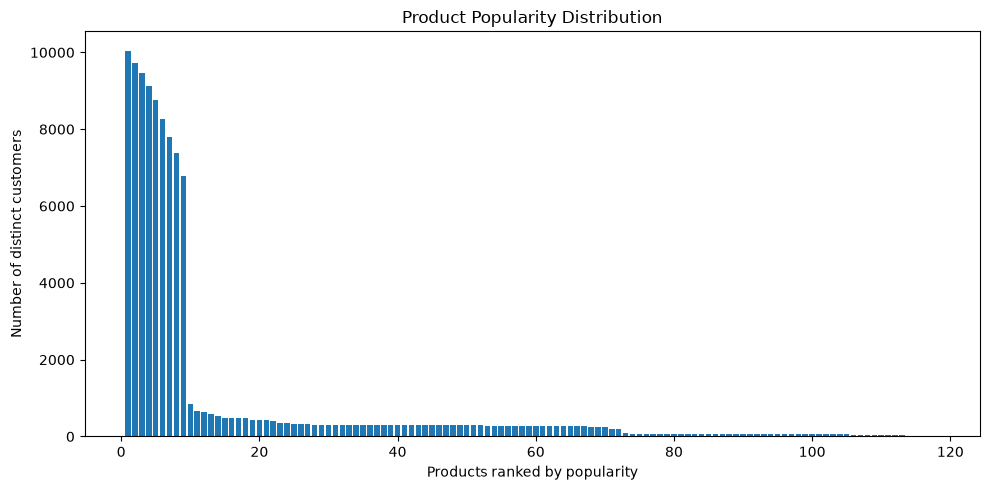

In [23]:
display(recommender.popularity_summary().round(2))
display(recommender.popularity.describe())
plot_product_popularity(recommender)


**Observations**

- The product popularity distribution confirms a substantial imbalance in the customer–product interaction matrix, with the top 20 products accounting for approximately 82% of all observed interactions. This indicates that customer purchases are highly concentrated in a relatively small group of products. Consequently, recommending the most popular products represents an effective strategy for this dataset, which may explain why the Popularity Baseline outperformed the Truncated SVD recommendation system.